# Gene expression associations

In this notebook, we're going to look for genes associated with clonal behaviour in [the dataset](https://www.science.org/doi/10.1126/science.aaw3381) with *in vitro* hematopoiesis. The question we're asking is which genes of the undifferentiated cells are associated with the fates of their differentiated siblings.

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import clone2vec as c2v

sc.set_figure_params(dpi=80)
sc.settings.verbosity = 3
sns.set_style("ticks")

## Clonal embedding

Let's start with a clonal embedding, exactly as in the introductory notebook: create an AnnData object with clones, build the clone-to-clone adjacency graph, and train clone2vec on it.

In [2]:
adata = c2v.datasets.Weinreb_in_vitro(embedding_type="gex")

using gene expression embedding
try downloading from url
https://zenodo.org/records/22644169/files/Weinreb_in_vitro_gex.h5ad
... this may take a while but only happens once


  0%|          | 0.00/1.42G [00:00<?, ?B/s]

In [11]:
clones = c2v.pp.clones_adata(
    adata,
    obs_name="Clone",
    min_size=2,
    na_value="NA",
    fill_obs="celltype",
)

creating clone-level AnnData
    selected 5864 clones (>= 2)
    finished (0:00:00): created clones AnnData with
     .X float matrix of proportions (clones × categories)
     .layers['proportions'] float matrix with fate proportions
     .layers['counts'] integer matrix with fate counts
     .obs['n_cells'] integer vector with number of cells per clone
     .obs['n_fates'] integer vector with number of fates per clone
     .var['n_clones'] integer vector with number of clones per fate
     .uns['fill_obs'] string label
     .uns['filtered_clones'] names and sizes of the clones smaller than min_size


In [12]:
c2v.tl.clonal_nn(adata, clones, use_rep="X_pca_harmony")

computing clone-to-clone adjacency graph
    finished (0:00:50): added
     .obsp['gex_adjacency'] clone adjacency graph.
     .uns['clonal_nn'] parameters.


In [13]:
c2v.tl.clone2vec(clones)

fitting clone2vec embeddings
    SG epochs:   9%|▉         | 46/500 [11:49<1:56:43, 15.43s/it, loss=6.3088, Δ=5.76e-05]
    early stopping at epoch 47
    finished (0:11:51): added
     .obsm['clone2vec'] embedding matrix
     .uns['clone2vec'] training details


In [14]:
sc.pp.neighbors(clones, use_rep="clone2vec")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:03)


In [15]:
sc.tl.umap(clones, min_dist=0.3)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:08)


In [16]:
sc.tl.leiden(clones, resolution=1, flavor="igraph", n_iterations=2)

running Leiden clustering
    finished: found 11 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


Leiden clusters of this embedding can be described by their fate composition.

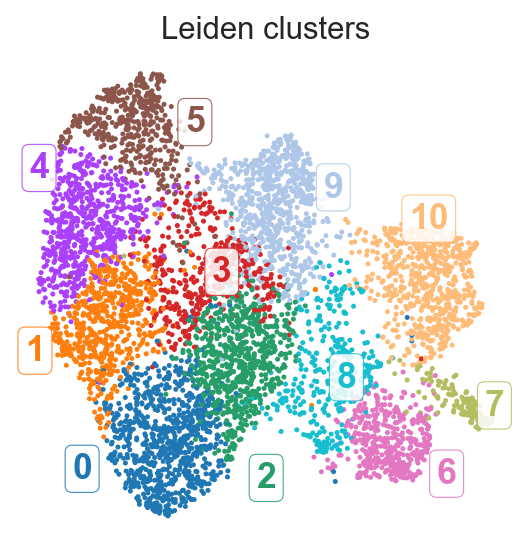

In [17]:
ax = sc.pl.umap(
    clones,
    color="leiden",
    show=False,
    frameon=False,
    title="Leiden clusters",
)

c2v.pl.fancy_legend(ax, center_loc=False, textsize=16, fontweight="bold")

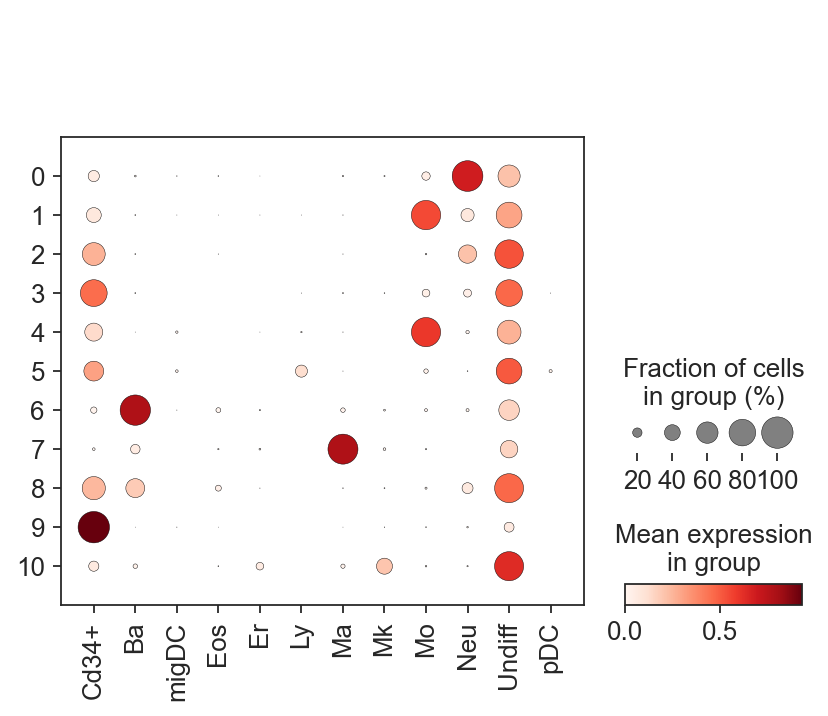

In [19]:
sc.pl.dotplot(clones, var_names=clones.var_names, groupby="leiden")

But the composition doesn't tell the whole story. Clones from clusters 1 and 4 produce similar proportions of monocytes, and differ mostly in their neutrophil output.

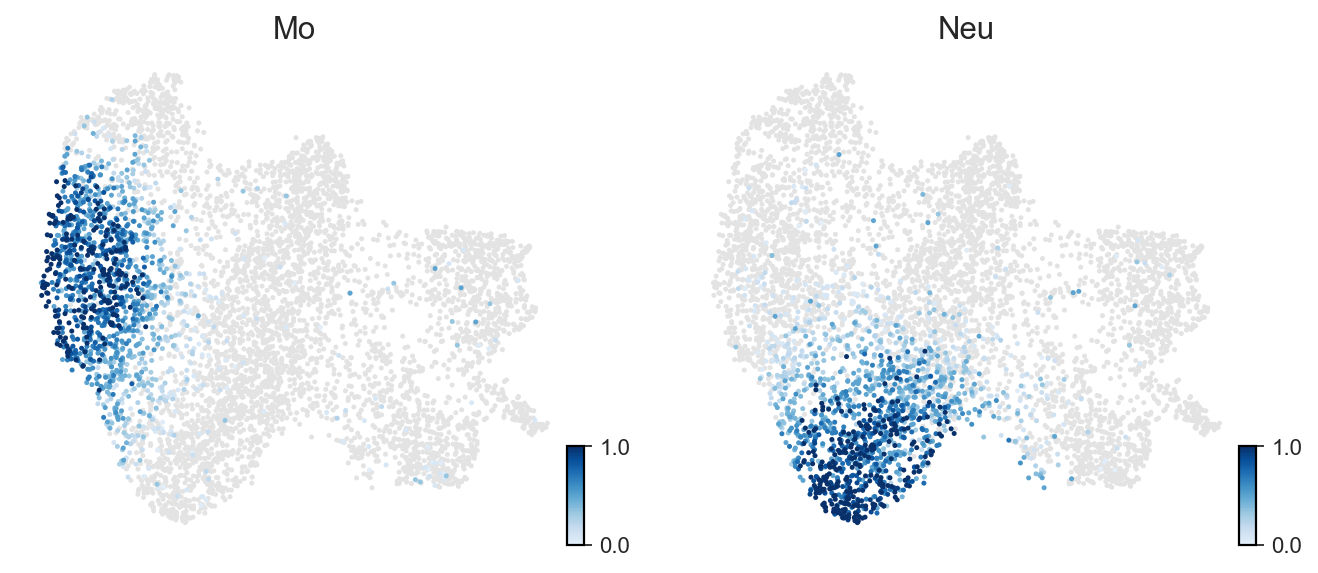

In [20]:
axes = sc.pl.umap(
    clones,
    color=["Mo", "Neu"],
    frameon=False,
    cmap=c2v.pl.Blues,
    show=False,
)

c2v.pl.small_cbar(axes)

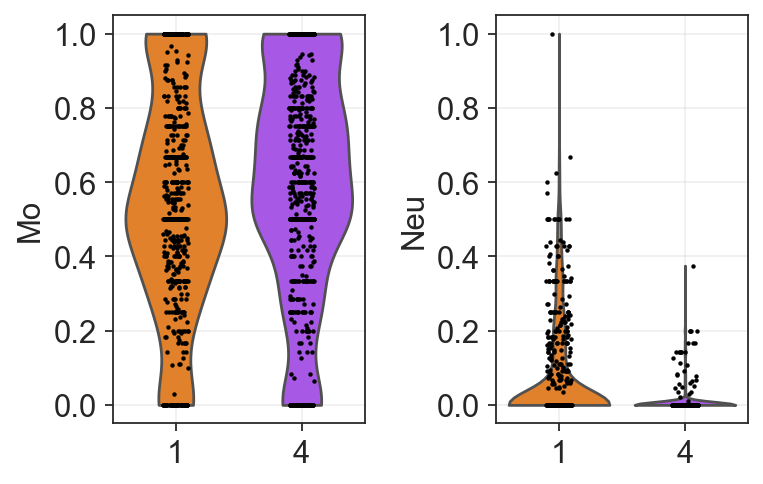

In [22]:
fig, axes = plt.subplots(figsize=(5, 3.5), ncols=2)

sc.pl.violin(
    clones[clones.obs.leiden.isin(["1", "4"])],
    keys=["Mo"],
    groupby="leiden",
    ax=axes[0],
    size=2,
    show=False,
)

sc.pl.violin(
    clones[clones.obs.leiden.isin(["1", "4"])],
    keys=["Neu"],
    groupby="leiden",
    ax=axes[1],
    size=2,
    show=False,
)

plt.tight_layout()
for ax in axes:
    ax.set_xlabel("")
    ax.grid(alpha=0.3)

After transferring clonal labels back to the cells, we can see that cells of these two clusters occupy different regions of the gene expression embedding as well.

In [23]:
c2v.pp.transfer_annotation(adata, clones, annotation_obs_clones="leiden")

transferring annotations between cell and clone objects
    finished (0:00:00): added to clonal AnnData
     .obs['c2v_leiden'] categorical labels


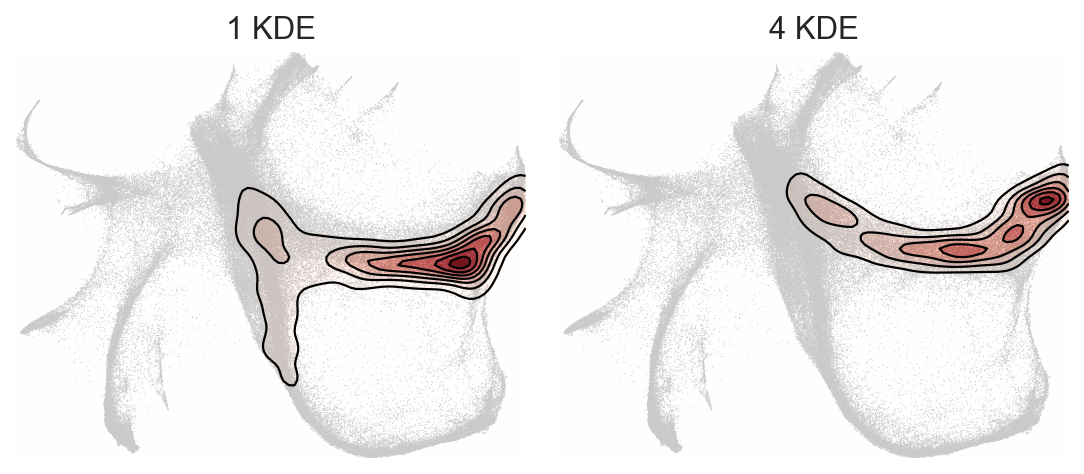

In [24]:
c2v.pl.group_kde(adata, groupby="c2v_leiden", groups=["1", "4"], basis="X_spring")

## Masking the undifferentiated cells

Now we can ask which genes of the undifferentiated cells are associated with the fate of a clone. To avoid circularity, we hide `Cd34+` cells during the embedding construction, so `clones.obsm["clone2vec_mask"]` describes the behaviour of the differentiated progeny only.

In [25]:
c2v.tl.mask_heterogeneity(adata, clones, mask=adata.obs.celltype == "Cd34+")

masking cells and refitting clone2vec embeddings
    computing clone-to-clone adjacency graph
    fitting clone2vec embeddings
        SG epochs:  10%|█         | 51/500 [12:19<1:48:31, 14.50s/it, loss=5.2253, Δ=6.83e-05]
        early stopping at epoch 52
    finished (0:12:33): added
     .obsm['clone2vec_mask'] embedding matrix.
     .uns['mask'] clonal_nn parameters and training details.


And we summarize the expression of exactly those cells that were hidden (`mask=True`), so the embedding isn't influenced by the expression in this cell population.

In [26]:
clones_gex = c2v.pp.transfer_expression(adata, clones, mask=True)

summarizing expression at clone level: 
    using `adata.X` as expression source
    finished (0:00:02): created clone-level AnnData with
     .X aggregated expression matrix (clones × genes)
     .uns['transfer_expression'] dict with aggregation parameters
     .obs['n_cells_expr'] number of cells used for aggregation
     .obsm['proportions'] dataframe of features
     .obsm['counts'] dataframe of features


In [27]:
sc.pp.filter_genes(clones_gex, min_cells=5)

filtered out 10457 genes that are detected in less than 5 cells


## Differential expression

Instead of comparing cluster labels directly, `c2v.tl.masked_markers()` scores every clone by the fraction of its neighbours in the masked embedding that belong to the test and the reference groups, and tests gene expression against this score.

In [28]:
de = c2v.tl.masked_markers(clones_gex, groupby="leiden", test="1", reference="4")

testing markers of 1 vs 4 along masked embedding: 
    using `clones.obsm['clone2vec_mask']` with 10 neighbours and regression test
    finished (0:00:00): returned DataFrame indexed by genes with 'scores', 'logfoldchanges', 'pvals', 'pvals_adj'
     525 clones used (216 test, 309 reference, 0 neighbouring)
     14024 genes tested (808 constant genes skipped)
     34 genes up and 23 down in test (pvals_adj < 0.05)


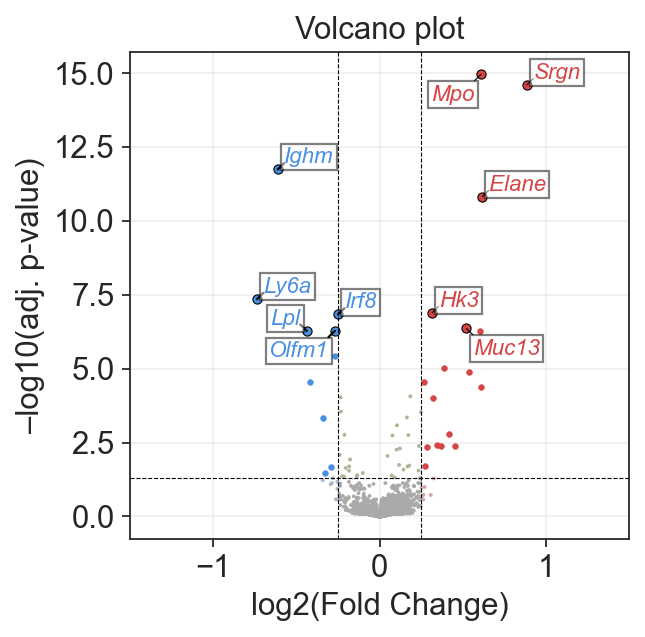

In [29]:
c2v.pl.volcano(de, logfc_threshold=0.25, xlim=(-1.5, 1.5))

It's always worth checking the trends behind the test:

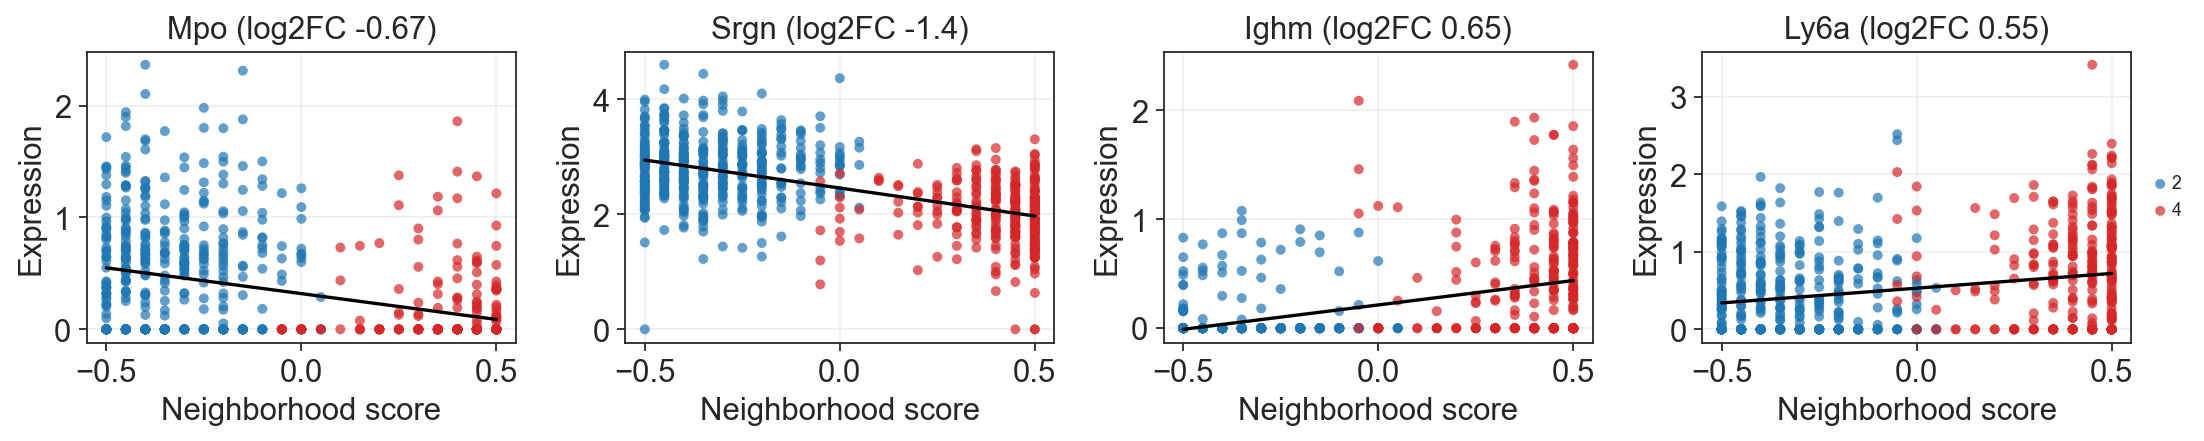

In [30]:
axes = c2v.pl.de_trend(
    clones_gex,
    genes=["Mpo", "Srgn", "Ighm", "Ly6a"],
    groupby="leiden",
    test="4",
    reference="2",
    show=False,
)

## Associations with the whole embedding

Instead of comparing two groups of clones, we can look for genes associated with the clonal embedding as a whole: `c2v.tl.graph_associations()` computes Moran's I and supervised PCA over the clonal graph, and `c2v.tl.associations()` correlates genes with the fate proportions directly.

In [31]:
c2v.tl.graph_associations(clones_gex, use_rep="clone2vec_mask")

computing graph associations
    scaling expression
    building kNN-graph on 'clone2vec_mask' with 10 neighbors
    computing Moran's I and sPCA
    finished (0:00:06): added
     .obsm['X_sPCA'] 50 supervised principal components
     .varm['sPCs'] matrix of loadings
     .uns['spca'] eigenvalues and variance explained
     .var['morans_i'] Moran's I statistics
     .var['morans_i_pval'], .var['morans_i_p_adj'] analytical p-values
     .uns['graph_associations'] parameters


In [32]:
c2v.tl.associations(clones_gex, response_key="proportions")

computing feature–response associations: 
    using `adata.X` as features
    using `adata.obsm['proportions']` as response
    computed 'pearson' statistics for 'X' features
    finished (0:00:00): added
     .varm['<response_key>:<feature matrix>:pearson:r'] matrix with correlation coefficients
     .varm['<response_key>:<feature matrix>:pearson:pvalue'] matrix with uncorrected p-values
     .varm['<response_key>:<feature matrix>:pearson:slope'] matrix with regression slopes coefficients
     .varm['<response_key>:<feature matrix>:pearson:p_adj'] matrix with corrected p-values


Genes with the highest Moran's I are the ones with the most structured expression across the clonal graph, and we can plot them on the clonal UMAP and check with which fates they're associated.

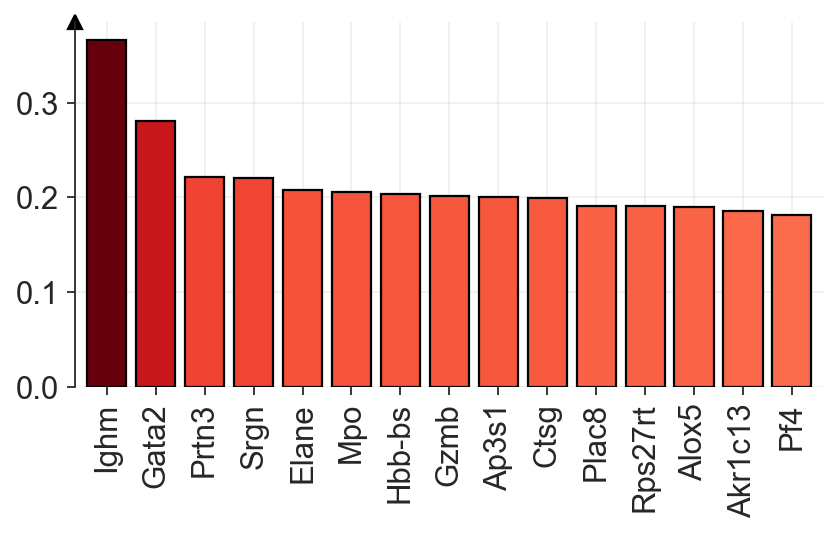

In [131]:
genes = clones_gex.var.sort_values("morans_i", ascending=False).index[:15]

c2v.pl.barplot(clones_gex.var.loc[genes].morans_i, kind="h")

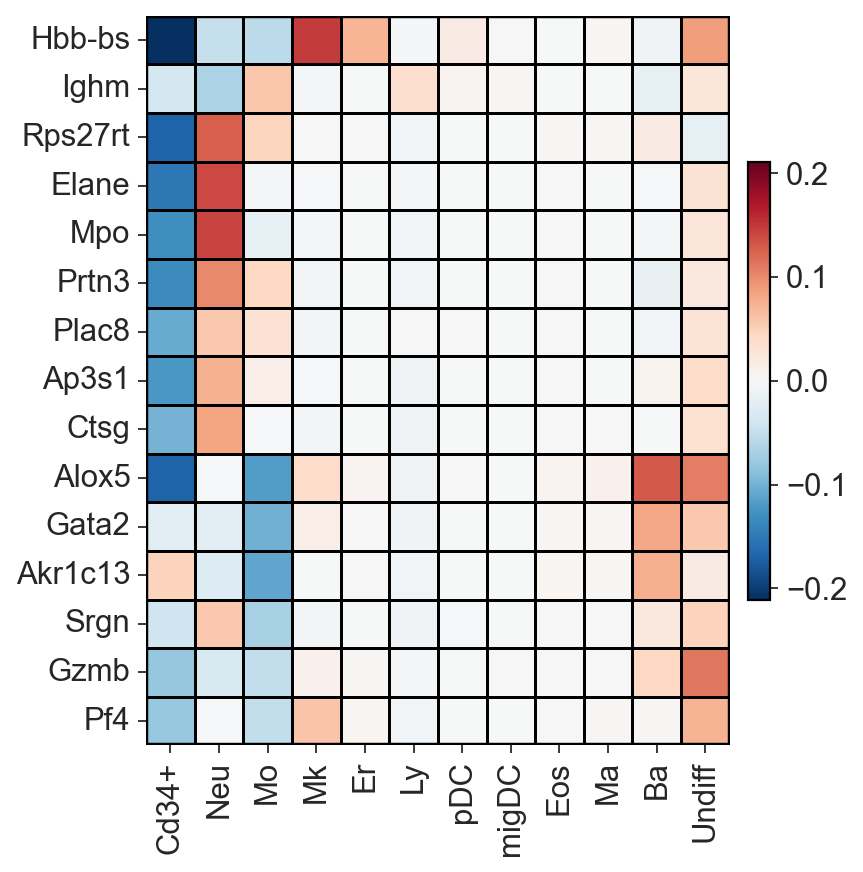

In [134]:
c2v.pl.heatmap(
    clones_gex.varm["proportions:X:pearson:slope"].loc[genes],
    sort_columns=True,
    sort_rows=True,
)

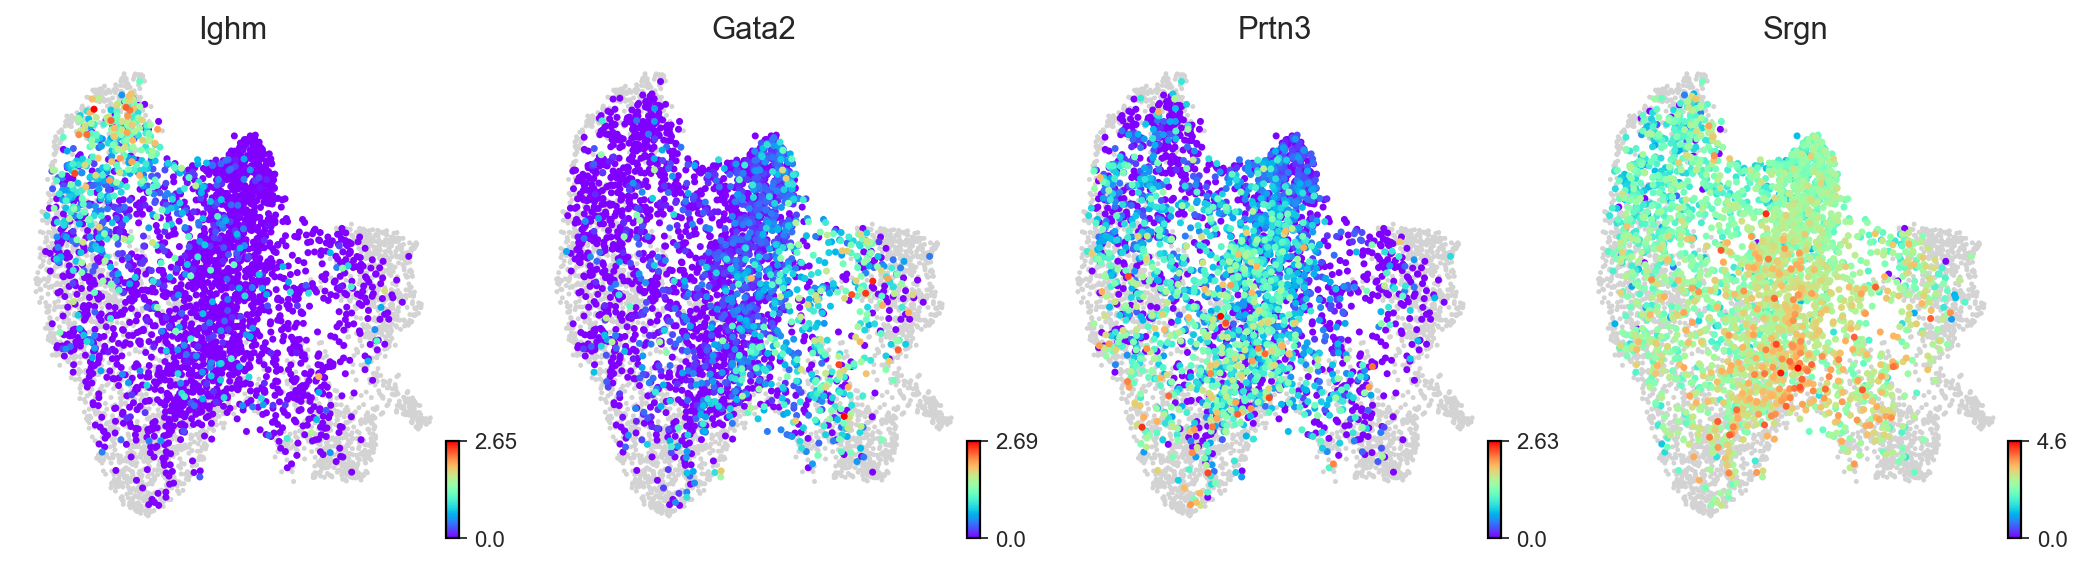

In [95]:
fig, axes = plt.subplots(ncols=4, figsize=(16, 4))

genes = clones_gex.var.sort_values("morans_i", ascending=False).index[:4]
for i, gene in enumerate(genes):
    ax = axes[i]
    sc.pl.umap(clones, show=False, frameon=False, s=20, ax=ax) # Background
    sc.pl.umap(
        clones_gex,
        ax=ax,
        show=False,
        color=gene,
        cmap="rainbow",
        s=40,
    )
    c2v.pl.small_cbar(ax)

Supervised principal components summarize this structure into a few axes, and we can correlate them with the fate proportions.

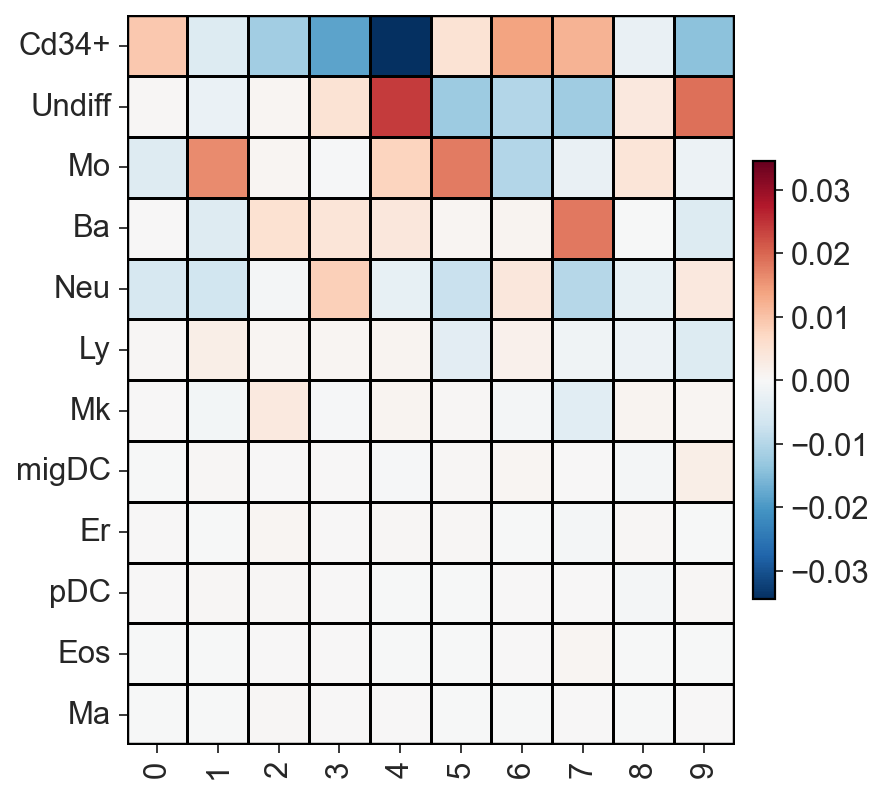

In [118]:
c2v.pl.heatmap(c2v.tl.fast_corr(
    clones_gex.obsm["X_sPCA"][:, :10],
    clones_gex.obsm["proportions"],
)["slope"].T, sort_rows=True, sort_columns=False)

And each component can be inspected together with its loadings.

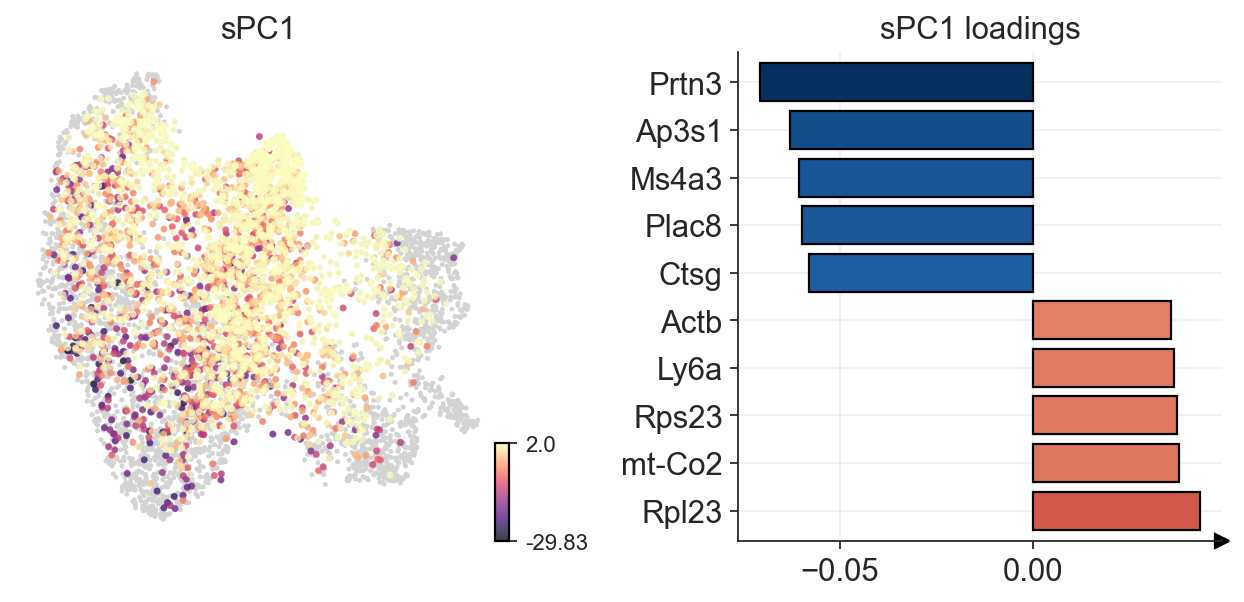

In [109]:
component = 1

fig, axes = plt.subplots(figsize=(8, 4), ncols=2)
sc.pl.umap(clones, show=False, frameon=False, s=20, ax=axes[0])
c2v.pl.embedding(
    clones_gex,
    obsm_component=component - 1,
    obsm_name="X_sPCA",
    ax=axes[0],
    show=False,
    color="Ighm",
    cmap="magma",
    s=40,
    vmax=2,
    alpha=0.75,
    title=f"sPC{component}",
)
c2v.pl.small_cbar(axes[0])
c2v.pl.pca_loadings(
    clones_gex,
    comp=component - 1,
    ax=axes[1],
)
plt.tight_layout()

And we can double-check that the behavior of individual genes is consistent.

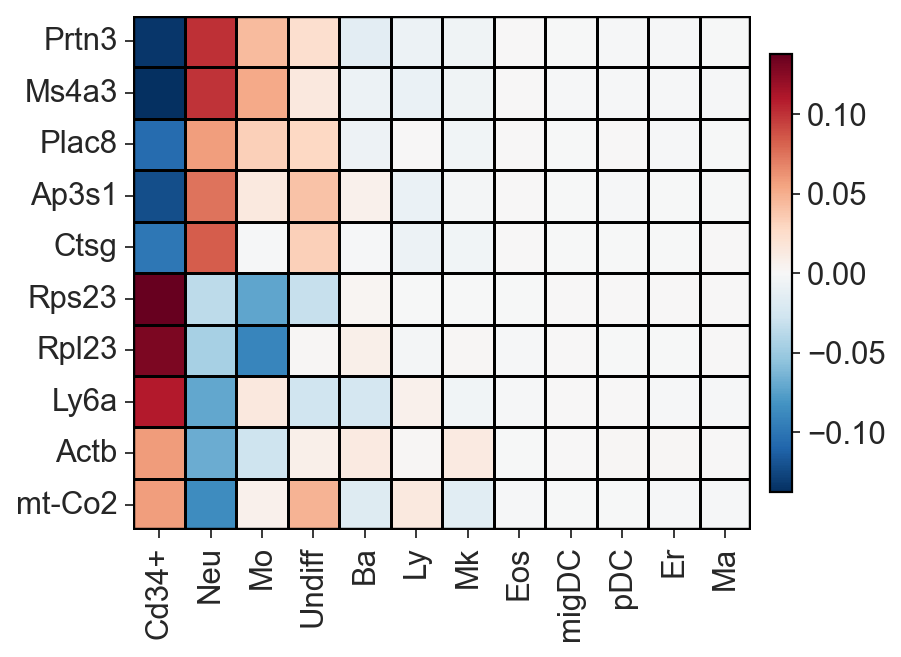

In [123]:
top_genes = list(clones_gex.var_names[np.argsort(clones_gex.varm["sPCs"][:, 0])][:5])
bottom_genes = list(clones_gex.var_names[np.argsort(clones_gex.varm["sPCs"][:, 0])][-5:])
genes = top_genes + bottom_genes

c2v.pl.heatmap(
    clones_gex.varm["proportions:X:pearson:slope"].loc[genes],
    sort_columns=True,
    sort_rows=True,
)